# 01 · Smoke test and covariates: how a flat result changed the project

PR #8 · session **A4** in the AI log · shared setup before Phase I

The original task idea was: *start with each location's own temperature history, then add its local
weather variables, then the temperatures of upstream (west) points, and see whether the forecast gets
better.* This notebook shows how a small AI-written smoke test turned that hypothesis around.

**How to read this notebook.** Each step starts with an *AI collaboration* box: what Sandro asked
(reconstructed from the PR description, not a verbatim quote), what the AI assistant proposed, how
it was checked by a human, and what was decided. The code below the box re-computes the evidence from
the repo, so the decision can be checked rather than believed. The full log is in
[`ai-interactions/phase1-ai-aided-pair.md`](../ai-interactions/phase1-ai-aided-pair.md).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def repo_root(start=None):
    start = start or Path.cwd()
    for p in [start, *start.parents]:
        if (p / "data_acquisition").is_dir() and (p / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the ai-vis-lab-2026 repo")

ROOT = repo_root()
DATA = ROOT / "data" / "austria_15km"
SITE = ROOT / "phase1-model-behavior" / "pair-1" / "dashboard" / "site" / "data"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 140)
print("repo:", ROOT.name, "| 15 km data present:", (DATA / "grid_long.parquet").exists())

repo: ai-vis-lab-2026 | 15 km data present: True


> **AI collaboration · A4, step 1 · smoke test**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | Write a smoke test that forecasts T2M 24 h ahead at random points with four input setups (own history, + local variables, + 4 west stations, + 4 east stations). Compare with persistence and same-hour-yesterday, at random and at cold-wave origins. |
> | **AI proposal** | <code>scripts/tirex_smoke_test.py</code>: 12 points × 8 origins on the 5 km grid, MAE by lead time and 10–90 % band coverage. |
> | **Human check** | Ran it in the container, read the tables. |
> | **Decision** | Result accepted. But the four input setups gave the same numbers, which needed an explanation. |

### Recorded result (PR #8, Austria 5 km, 12 locations × 8 origins)

These numbers are copied from the PR description. They were produced inside the Docker container with
TiRex-2; this notebook does not re-run that part (see the live cell further down).

In [2]:
smoke = pd.DataFrame(
    [["persistence",          0.89, 3.95, 2.09, 3.77, 5.79, np.nan, np.nan],
     ["same hour yesterday",  1.79, 2.28, 2.09, 4.43, 5.79, np.nan, np.nan],
     ["TiRex-2, own history", 0.45, 1.44, 2.19, 2.37, 4.97, 0.87, 0.58],
     ["+ local variables",    0.45, 1.43, 2.18, 2.40, 4.99, 0.87, 0.59],
     ["+ 4 west stations",    0.45, 1.43, 2.18, 2.38, 4.98, 0.87, 0.59],
     ["+ 4 east stations",    0.45, 1.43, 2.19, 2.38, 4.97, 0.87, 0.59]],
    columns=["setup", "random 1h", "random 6h", "random 24h", "cold wave 6h", "cold wave 24h",
             "cover random", "cover cold wave"]).set_index("setup")
tirex_rows = smoke.index[2:]
print("largest change from extra input (K):",
      (smoke.loc[tirex_rows, smoke.columns[:5]] - smoke.loc["TiRex-2, own history", smoke.columns[:5]]).abs().max().max())
smoke

largest change from extra input (K): 0.029999999999999805


,random 1h,random 6h,random 24h,cold wave 6h,cold wave 24h,cover random,cover cold wave
setup,,,,,,,
persistence,0.89,3.95,2.09,3.77,5.79,NaN,NaN
same hour yesterday,1.79,2.28,2.09,4.43,5.79,NaN,NaN
"TiRex-2, own history",0.45,1.44,2.19,2.37,4.97,0.87,0.58
+ local variables,0.45,1.43,2.18,2.40,4.99,0.87,0.59
+ 4 west stations,0.45,1.43,2.18,2.38,4.98,0.87,0.59
+ 4 east stations,0.45,1.43,2.19,2.38,4.97,0.87,0.59


**What a human notices.** Two things stand out:

1. TiRex-2 beats both baselines up to about 12 h, and at cold waves the 10–90 % band covers only
   **58 %** instead of 80 %: the model is overconfident exactly when it matters. This later became a main
   thread of Phase I (notebook 03).
2. Adding local variables or eight neighbouring stations changes the error by **at most 0.03 K**. Either
   upstream information really does not help, or the model does not use it.

> **AI collaboration · A4, step 2 · synthetic covariate check**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | The extra inputs change nothing. Is that our data or the model? Build a test where the answer is known. |
> | **AI proposal** | A synthetic check with random walks: a past covariate that runs 12 h <i>ahead</i> of the target (a perfect early indicator), pure noise as past covariate, and the target itself as <i>future</i> covariate (upper bound). |
> | **Human check** | Read the code; the test is model-only and uses no real data, so it cannot leak information from the dataset. |
> | **Decision** | Accepted. It explained the flat result and changed the multi-station hypothesis. |

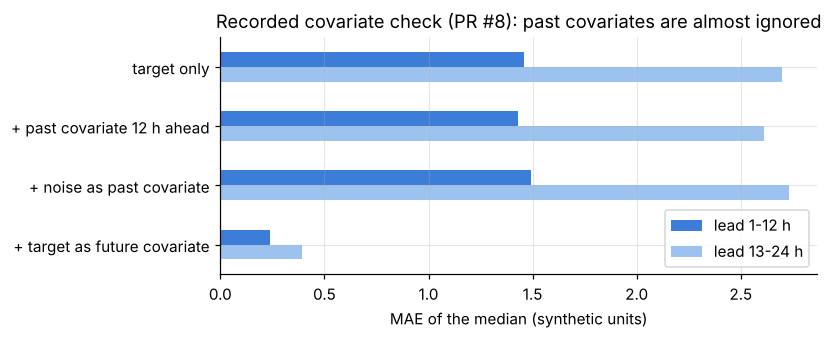

,lead 1-12 h,lead 13-24 h
target only,1.46,2.70
+ past covariate 12 h ahead,1.43,2.61
+ noise as past covariate,1.49,2.73
+ target as future covariate,0.24,0.39


In [3]:
cov = pd.DataFrame({"lead 1-12 h": [1.46, 1.43, 1.49, 0.24], "lead 13-24 h": [2.70, 2.61, 2.73, 0.39]},
                   index=["target only", "+ past covariate 12 h ahead", "+ noise as past covariate",
                          "+ target as future covariate"])
ax = cov.plot.barh(figsize=(7, 2.8), color=["#3b7dd8", "#9cc3f0"])
ax.invert_yaxis(); ax.set_xlabel("MAE of the median (synthetic units)")
ax.set_title("Recorded covariate check (PR #8): past covariates are almost ignored")
plt.show()
cov

**Live re-run.** The cell below runs the same check with the real model *if* `tirex2` is installed and the
weights can be downloaded (the Docker image has both). Otherwise it says so and the recorded numbers above
stand.

In [4]:
try:
    import torch  # noqa: F401
    from tirex2 import load_model
    sys.path.insert(0, str(ROOT / "scripts"))
    from tirex_smoke_test import covariate_check
    covariate_check(load_model("NX-AI/TiRex-2", device="cpu"))
except (ImportError, OSError, RuntimeError) as e:  # no torch / tirex2 / weights in this environment
    print(f"skipped live re-run ({type(e).__name__}: {e}).")
    print("Run inside the container: docker compose run --rm lab python scripts/tirex_smoke_test.py --covariate-check")

skipped live re-run (ModuleNotFoundError: No module named 'torch').
Run inside the container: docker compose run --rm lab python scripts/tirex_smoke_test.py --covariate-check


## Does the picture hold on the Phase I data?

The Phase I forecasts (`run_forecasts.py`, PR #14) use **only the temperature history** of each point,
because of this finding. The dashboard stores 38 of these runs in full (30 starts 6 or 12 h before a cold
front, plus a calm, a thunderstorm and six normal days), for all 378 points. We can compare them with the
same two baselines as the smoke test, without running the model again.

In [5]:
meta = json.loads((SITE / "forecast_runs.json").read_text())
C, H = meta["ctx"], meta["h"]
runs = np.fromfile(SITE / "forecast_runs.bin", "<i2").reshape(len(meta["runs"]), meta["n"], meta["stride"]) / meta["scale"]
ctx, truth = runs[..., :C], runs[..., C:C + H]
q10, q50, q90 = runs[..., C + H:C + 2 * H], runs[..., C + 2 * H:C + 3 * H], runs[..., C + 3 * H:]
kind = np.array(["before a cold front" if r["kind"] == "front" else "other days" for r in meta["runs"]])
persistence = np.repeat(ctx[..., -1:], H, axis=-1)
yesterday = ctx[..., C - 24:C - 24 + H]          # same hour the day before (context is 36 h)

rows = []
for k in ["other days", "before a cold front"]:
    m = kind == k
    for name, f in [("TiRex-2", q50), ("persistence", persistence), ("same hour yesterday", yesterday)]:
        mae = np.abs(f[m] - truth[m]).mean(axis=(0, 1))
        rows.append({"runs": k, "forecast": name, **{f"{h} h": mae[h - 1] for h in [1, 6, 12, 24]}})
    cover = ((truth[m] >= q10[m]) & (truth[m] <= q90[m])).mean(axis=(0, 1)) * 100
    rows.append({"runs": k, "forecast": "TiRex-2 10-90 % band coverage %", **{f"{h} h": cover[h - 1] for h in [1, 6, 12, 24]}})
print({k: int((kind == k).sum()) for k in np.unique(kind)}, "runs x", meta["n"], "points")
pd.DataFrame(rows).set_index(["runs", "forecast"]).round(2)

{np.str_('before a cold front'): 30, np.str_('other days'): 8} runs x 378 points


1 h    6 h   12 h   24 h
runs                forecast                                                   
other days          TiRex-2                           0.48   1.12   1.32   2.46
                    persistence                       0.90   2.51   5.86   2.28
                    same hour yesterday               2.51   1.96   1.97   2.28
                    TiRex-2 10-90 % band coverage %  88.10  87.70  91.44  78.74
before a cold front TiRex-2                           0.63   1.86   2.65   5.37
                    persistence                       1.06   4.33   6.32   5.85
                    same hour yesterday               3.12   3.23   3.21   5.85
                    TiRex-2 10-90 % band coverage %  83.00  72.67  62.78  39.23

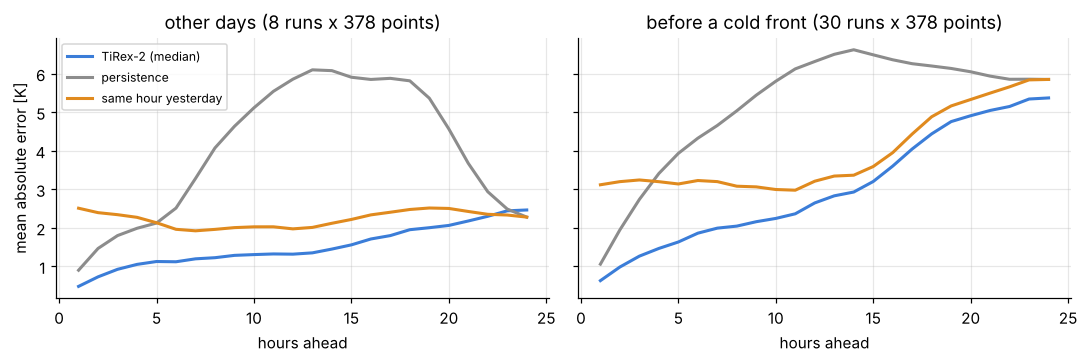

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
leads = np.arange(1, H + 1)
for ax, k in zip(axes, ["other days", "before a cold front"]):
    m = kind == k
    for name, f, c in [("TiRex-2 (median)", q50, "#3b7dd8"), ("persistence", persistence, "0.55"),
                       ("same hour yesterday", yesterday, "#e08a1e")]:
        ax.plot(leads, np.abs(f[m] - truth[m]).mean(axis=(0, 1)), label=name, color=c, lw=2)
    ax.set_title(f"{k} ({m.sum()} runs x {meta['n']} points)"); ax.set_xlabel("hours ahead")
axes[0].set_ylabel("mean absolute error [K]"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

The pattern from the smoke test holds on the Phase I runs: TiRex-2 wins clearly in the first hours, the
advantage is gone by 24 h (on these few "other days" runs a simple baseline is even slightly better at
24 h), and before cold fronts both the error and the miscalibration grow (band coverage far below 80 %).
These 38 runs are examples stored for the dashboard; the systematic numbers over all 336 runs are in
notebook 03.

> **AI collaboration · A4 → Phase I · decision**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | (team discussion, not an AI prompt) |
> | **AI proposal** | Pass upstream series <i>shifted in time</i> as future covariates: a west station observed at t − s is known for the next s hours. |
> | **Human check** | Kept as an open team decision; the correction 'past covariates did not change the forecast in our smoke test' was added to <code>model-selection.md</code> in PR #15. |
> | **Decision** | Phase I forecasts use the temperature history only; 'do neighbours help?' moved from an assumption to a tested question: Carlos's Phase I experiments gave the model upstream temperatures (40-240 km) and pressure, humidity and wind, and found no improvement over temperature alone (see `phase1-model-behavior/pair-1/experiments/`). |

### What this step shows about the collaboration

- The AI wrote the experiment, but the **interesting move was reacting to a boring result**: four
  identical rows were a signal, not a failure.
- The synthetic test is a pattern worth keeping: when a result is flat or surprising, ask for a test where
  the right answer is known.
- The AI's suggestion (shifted future covariates) was **not** adopted automatically. It changes the task,
  so it went to the team.